## Seleção de características e classificação

*Kalil Nege — RA 2409020 · OPT098 - Tópicos Especiais em Sistemas de Computação (Prof. Dr. Rodrigo Hübner)*

Etapas:

1. **Classificação por voto** (sem treino), como em `classifier_per_freq.ipynb`: o alvo previsto é aquele com o maior valor da característica;
2. **Classificação supervisionada** com `SVM` (sugerida no `beta_ml.ipynb`), comparada com LDA, k-NN e floresta aleatória;
3. **Seleção de características** com `RFE`, variando `n_features_to_select`;
4. Comparação entre os grupos de características: SSVEP, ritmos e fusão.

#### Validação

Janelas de um mesmo ensaio de 30 s são muito parecidas entre si. Se forem divididas aleatoriamente, janelas "irmãs" caem no treino e no teste e a acurácia fica **inflada** (vazamento de dados). Por isso uso:

- `GroupKFold` (5 partições) agrupando por **ensaio**: modelo dependente de participante, sem vazamento entre janelas;
- `LeaveOneGroupOut` agrupando por **participante**: modelo independente de participante (entre participantes), que é o cenário mais difícil.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
import warnings
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut, cross_validate, cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay

warnings.filterwarnings('ignore')
FREQS = [6.0, 6.5, 7.0, 7.5, 8.2, 9.3, 10.0]
NOMES = list(np.load('dados/nomes_caracteristicas.npy'))
IDX_SSVEP = np.arange(28)
IDX_RITMOS = np.arange(28, 35)


def carrega(nome):
    F = np.load(f'dados/{nome}_caracteristicas.npy')
    meta = np.load(f'dados/{nome}_epocas_meta.npy')
    y = meta[:, 0].astype(str)  # rótulo categórico (evita o erro de "continuous")
    return F, y, meta[:, 1].astype(int), meta[:, 2].astype(int)


dados = {nome: carrega(nome) for nome in ('single', 'multi')}
for nome, (F, y, ensaio, suj) in dados.items():
    print(f'{nome}: {F.shape[0]} janelas, {len(set(ensaio))} ensaios, {len(set(suj))} participantes')

single: 644 janelas, 92 ensaios, 4 participantes
multi: 400 janelas, 100 ensaios, 5 participantes


### 1. Classificação por voto (sem treinamento)

In [2]:
from sklearn.metrics import balanced_accuracy_score

print(f"{'característica':<12} {'single':>8} {'multi':>8}")
for tipo, desloc in (('psd_max', 0), ('snr_f1', 1), ('cca', 3)):
    linha = f'{tipo:<12}'
    for nome, (F, y, ensaio, suj) in dados.items():
        valores = F[:, desloc:28:4]
        previsto = np.array(FREQS)[valores.argmax(axis=1)].astype(str)
        linha += f' {100 * (previsto == y).mean():>7.1f}%'
    print(linha)

característica   single    multi
psd_max         54.2%    52.2%
snr_f1          56.4%    52.8%
cca             78.3%    82.5%


O voto com o `cca` já supera 75% nos dois bases de dados sem nenhum treinamento, porque usa os harmônicos. Para referência, o acaso é de 1/7 ≈ 14% no *single target*.

### 2. Classificação supervisionada

In [3]:
classificadores = {
    'SVM (RBF)': make_pipeline(StandardScaler(), SVC(C=1.0)),
    'LDA': make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()),
    'k-NN (k=5)': make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
    'Floresta aleatória': RandomForestClassifier(300, random_state=0),
}

grupos_carac = {'SSVEP': IDX_SSVEP, 'Ritmos': IDX_RITMOS, 'Fusão': np.arange(35)}


def avalia(modelo, F, y, grupos, cv):
    r = cross_validate(modelo, F, y, groups=grupos, cv=cv, scoring=['accuracy', 'balanced_accuracy'])
    return 100 * r['test_accuracy'].mean(), 100 * r['test_balanced_accuracy'].mean()


resultados = []
for nome, (F, y, ensaio, suj) in dados.items():
    for nome_grupo, idx in grupos_carac.items():
        for nome_modelo, modelo in classificadores.items():
            acur_e, bal_e = avalia(modelo, F[:, idx], y, ensaio, GroupKFold(5))
            acur_p, bal_p = avalia(modelo, F[:, idx], y, suj, LeaveOneGroupOut())
            resultados.append((nome, nome_grupo, nome_modelo, acur_e, bal_e, acur_p, bal_p))

print(f"{'dataset':<7} {'grupo':<7} {'classificador':<18} | {'por ensaio':^15} | {'entre participantes':^19}")
print(f"{'':<35}| {'acur':>6} {'bal':>7} | {'acur':>8} {'bal':>9}")
for r in resultados:
    print(f'{r[0]:<7} {r[1]:<7} {r[2]:<18} | {r[3]:>6.1f} {r[4]:>7.1f} | {r[5]:>8.1f} {r[6]:>9.1f}')

dataset grupo   classificador      |   por ensaio    | entre participantes
                                   |   acur     bal |     acur       bal
single  SSVEP   SVM (RBF)          |   73.8    75.3 |     74.6      75.8
single  SSVEP   LDA                |   76.7    78.0 |     76.4      77.8
single  SSVEP   k-NN (k=5)         |   67.0    68.4 |     66.4      67.4
single  SSVEP   Floresta aleatória |   76.9    78.9 |     76.0      77.5
single  Ritmos  SVM (RBF)          |   18.8    20.8 |     18.0      18.9
single  Ritmos  LDA                |   18.7    21.0 |     20.3      21.2
single  Ritmos  k-NN (k=5)         |   21.0    21.7 |     21.3      21.9
single  Ritmos  Floresta aleatória |   20.7    23.4 |     21.3      22.2
single  Fusão   SVM (RBF)          |   71.6    73.5 |     69.8      71.3
single  Fusão   LDA                |   75.3    77.0 |     73.5      75.2
single  Fusão   k-NN (k=5)         |   63.2    64.5 |     63.0      63.8
single  Fusão   Floresta aleatória |   75.5    77

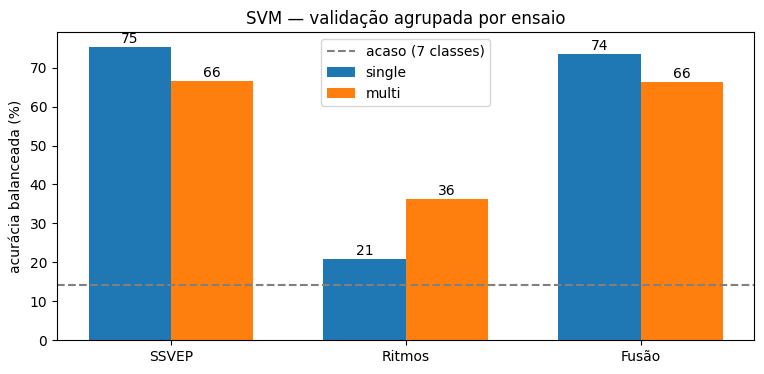

In [4]:
# gráfico comparando os grupos de características (SVM, validação por ensaio)
rcParams['figure.figsize'] = [9., 4.]
largura = 0.35
for k, nome in enumerate(('single', 'multi')):
    vals = [r[4] for r in resultados if r[0] == nome and r[2] == 'SVM (RBF)']
    plt.bar(np.arange(3) + k * largura, vals, largura, label=nome)
    for x, v in zip(np.arange(3) + k * largura, vals):
        plt.text(x, v + 1, f'{v:.0f}', ha='center')
plt.axhline(100 / 7, ls='--', c='gray', label='acaso (7 classes)')
plt.xticks(np.arange(3) + largura / 2, grupos_carac.keys())
plt.ylabel('acurácia balanceada (%)'); plt.title('SVM — validação agrupada por ensaio')
plt.legend(); plt.show()

### 3. Seleção de características com RFE

Como sugerido no `beta_ml.ipynb`, aplico o `RFE` com um SVM linear (que fornece os pesos `coef_` usados no ranqueamento), variando `n_features_to_select`. A seleção fica **dentro do *pipeline***, então é refeita em cada partição de treino e não "enxerga" o teste.

 3 características -> 53.0%


 5 características -> 72.1%


 7 características -> 79.6%


10 características -> 77.7%


14 características -> 75.8%


21 características -> 74.2%


28 características -> 73.2%
35 características -> 73.5%


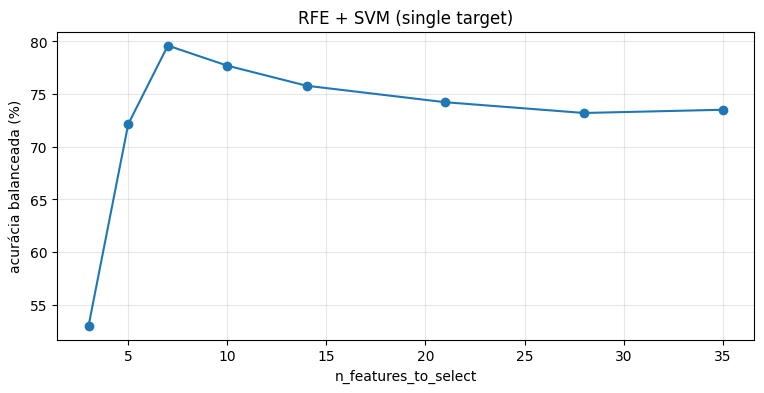

In [5]:
F, y, ensaio, suj = dados['single']
n_carac = [3, 5, 7, 10, 14, 21, 28, 35]
curva = []
for n in n_carac:
    modelo = make_pipeline(StandardScaler(),
                        RFE(SVC(kernel='linear'), n_features_to_select=n),
                        SVC(C=1.0))
    curva.append(avalia(modelo, F, y, ensaio, GroupKFold(5))[1])
    print(f'{n:>2} características -> {curva[-1]:.1f}%')

plt.plot(n_carac, curva, 'o-')
plt.xlabel('n_features_to_select'); plt.ylabel('acurácia balanceada (%)')
plt.title('RFE + SVM (single target)'); plt.grid(alpha=.3); plt.show()

In [6]:
# quais características o RFE mantém quando treinado com todos os dados
rfe = make_pipeline(StandardScaler(), RFE(SVC(kernel='linear'), n_features_to_select=10)).fit(F, y)
mantidas = np.array(NOMES)[rfe[-1].support_]
print('10 características selecionadas:', list(mantidas))

10 características selecionadas: [np.str_('psd_max_6.0'), np.str_('cca_6.0'), np.str_('snr_f2_6.5'), np.str_('cca_6.5'), np.str_('cca_7.0'), np.str_('cca_7.5'), np.str_('cca_8.2'), np.str_('cca_9.3'), np.str_('cca_10.0'), np.str_('rel_teta')]


### Matriz de confusão do melhor cenário

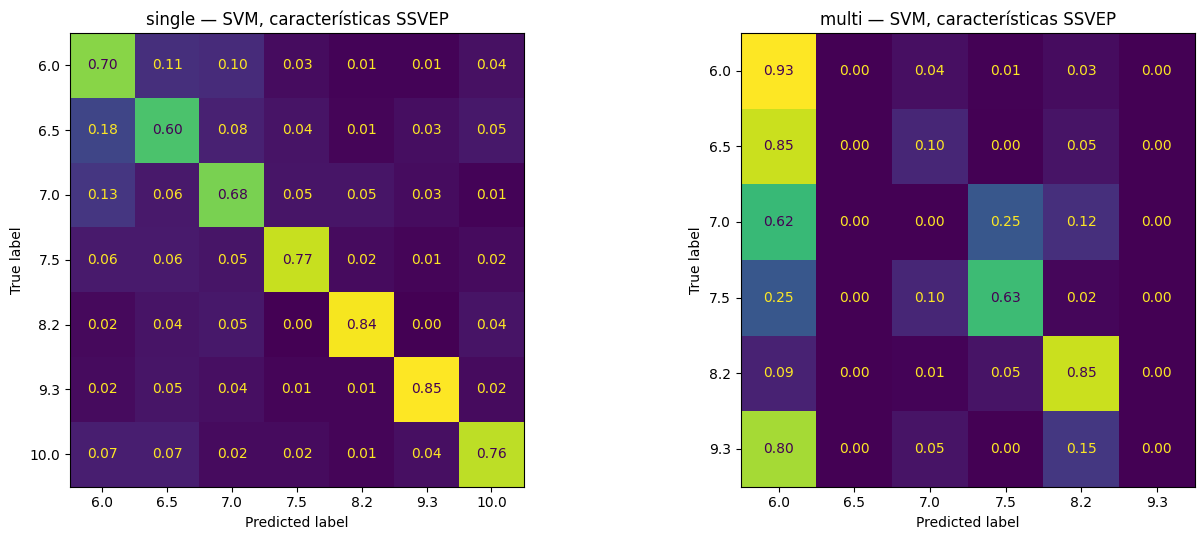

In [7]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 5.5))
for eixo, nome in zip(eixos, ('single', 'multi')):
    F, y, ensaio, suj = dados[nome]
    modelo = make_pipeline(StandardScaler(), SVC(C=1.0))
    previsto = cross_val_predict(modelo, F[:, IDX_SSVEP], y, groups=ensaio, cv=GroupKFold(5))
    rotulos = sorted(set(y), key=float)
    ConfusionMatrixDisplay.from_predictions(y, previsto, labels=rotulos, ax=eixo, colorbar=False,
                                            normalize='true', values_format='.2f')
    eixo.set_title(f'{nome} — SVM, características SSVEP')
plt.tight_layout(); plt.show()

### Conclusões desta etapa

- As características **SSVEP** são as que identificam o alvo. A correlação com referências (CCA) é a mais forte individualmente: com 10 características, o RFE mantém as 7 correlações CCA. O melhor resultado (≈80% de acurácia balanceada) aparece com apenas 7 características, acima do SVM com o vetor completo (≈73%), o que mostra que a seleção remove características redundantes ou ruidosas.
- As características de **ritmos** ficam próximas do acaso para identificar a frequência, como previsto: elas medem o estado de atenção, não a direção do olhar. Juntá-las ao vetor SSVEP (fusão) **não melhora** a identificação do alvo.
- As características de ritmos ficam acima do acaso no *multi target* (≈35%) porque, como visto no notebook 03, teta e alfa carregam parte do próprio SSVEP, e não por medirem atenção.
- No *multi target*, a validação entre participantes deu acurácia **maior** que a validação por ensaio (ex.: LDA com 80,5% × 67,2%), o que é incomum. Uma hipótese é o desbalanceamento: há apenas 5 ensaios de 6,5 Hz e de 9,3 Hz, então os partições por ensaio ficam com pouquíssimos exemplos dessas classes. Por isso a acurácia balanceada é a métrica mais confiável aqui, e esse ponto merece investigação.
- Com um único canal (Oz), métodos espaciais como CCA multicanal, TRCA ou as redes dos artigos estudados (DBAFN, *task attention*) não se aplicam diretamente. Esse é o principal ganho esperado ao migrar o mesmo roteiro para a base **BETA** (64 canais, 40 alvos).